# Time-resolved Go vs No-Go distance: model A vs model B

Pick one checkpoint from each of two models (and a task). Both models are run on the *same* simulated trials. Following the paper's definition: each unit's activity is Z-scored, only responsive units are kept (`responsive_criteria.json`), and the single-neuron distance is |r̄_Go − r̄_NoGo| of the class-mean responses. Curves show its mean ± SEM across units at every time bin; epoch values average each unit's responses over the epoch first. Epoch means are compared across units with Welch's t-test (units of two different networks are unpaired).

In [36]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

sys.path.insert(0, os.getcwd())
from neuron_discrimination import time_resolved_distance
%matplotlib inline

In [37]:
# ── set up ────────────────────────────────────────────────────────────────
env_file = Path.cwd().parent / '.env'
if env_file.exists():
    for line in env_file.read_text().splitlines():
        line = line.strip()
        if '=' in line and not line.startswith('#'):
            key, _, val = line.partition('=')
            os.environ.setdefault(key.strip(), val.strip())

results_dir = Path(os.environ.get('TONE_RESULTS_DIR', ''))
if not results_dir:
    sys.exit('TONE_RESULTS_DIR is not set. Add it to .env or export it.')

# the two checkpoints to compare: label, model dir, checkpoint step
A = dict(label='HCT',
         model_dir=results_dir / 'harmonic/harmonic_0_lr0.0001_bs64_noise0.1_nrnn128',
         step=6400)
B = dict(label='PT-HCT',
         model_dir=results_dir / 'transfer_pure_to_harmonic/context+sensory/harmonic/harmonic_0_lr0.0001_bs64_noise0.1_nrnn128',
         step=6400)

TASK = 'harmonic'    # stimulus set both models are tested on
N_TRIALS = 512
SEED = 0             # same seed -> both models see identical trials

# True : keep only stimulus-responsive units (criteria in responsive_criteria.json)
# False: use all units
RESPONSIVE_ONLY = True

# epochs (ms from stimulus onset) for the summary bars
EPOCHS = {'pre-alternation': (0, 60), 'first alternation': (60, 120), 'sustained': (120, 300)}

T_MIN_MS = 0         # time curves start here (ms from stimulus onset)
T_MAX_MS = 300       # time curves are cut off here (ms from stimulus onset)

In [38]:
ra = time_resolved_distance(A['model_dir'], A['step'], task=TASK, n_trials=N_TRIALS, seed=SEED,
                            responsive_only=RESPONSIVE_ONLY)
rb = time_resolved_distance(B['model_dir'], B['step'], task=TASK, n_trials=N_TRIALS, seed=SEED,
                            responsive_only=RESPONSIVE_ONLY)
assert np.array_equal(ra['t_ms'], rb['t_ms']), 'models have different trial timing'
t = ra['t_ms']
print(f"units used ({'responsive only' if RESPONSIVE_ONLY else 'all units'}): "
      f"{A['label']} {len(ra['units'])}, {B['label']} {len(rb['units'])}")

# single-neuron distance |mean Go - mean No-Go|: mean and SEM across units, per time step
pa, pb = ra['per_neuron'], rb['per_neuron']          # (T, n_units)
mean_a, sem_a = pa.mean(1), pa.std(1, ddof=1) / np.sqrt(pa.shape[1])
mean_b, sem_b = pb.mean(1), pb.std(1, ddof=1) / np.sqrt(pb.shape[1])
# units of two different networks are not paired, so the difference SEM is unpaired
diff, sem_diff = mean_b - mean_a, np.sqrt(sem_a**2 + sem_b**2)

units used (responsive only): HCT 66, PT-HCT 75


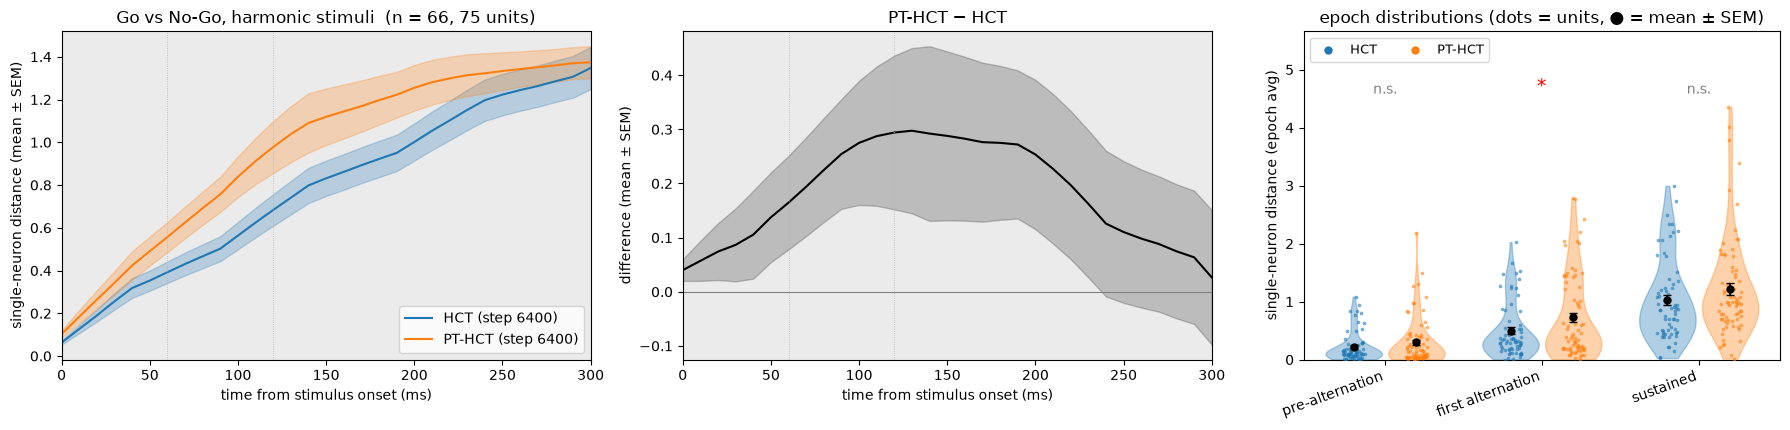

,HCT,PT-HCT,diff (B−A),t,p (Welch)
epoch,,,,,
pre-alternation,0.216787,0.298579,0.081792,1.447238,0.150301
first alternation,0.496389,0.728105,0.231715,2.287791,0.023770
sustained,1.026691,1.217546,0.190855,1.451813,0.148820


In [39]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.4), gridspec_kw={'width_ratios': [2, 2, 1.8]})
on, off = ra['stim_ms']
vis = (t >= T_MIN_MS) & (t <= T_MAX_MS)    # plot only T_MIN_MS..T_MAX_MS
COL_A, COL_B = 'C0', 'C1'                   # same colours as the curves

ax = axes[0]
for lab, step, m, s, col in [(A['label'], A['step'], mean_a, sem_a, COL_A),
                             (B['label'], B['step'], mean_b, sem_b, COL_B)]:
    ax.plot(t[vis], m[vis], color=col, label=f'{lab} (step {step})')
    ax.fill_between(t[vis], (m - s)[vis], (m + s)[vis], color=col, alpha=0.25)
ax.set(xlabel='time from stimulus onset (ms)',
       ylabel='single-neuron distance (mean ± SEM)',
       title=f'Go vs No-Go, {TASK} stimuli  (n = {pa.shape[1]}, {pb.shape[1]} units)')
ax.legend()

ax = axes[1]
ax.plot(t[vis], diff[vis], color='k')
ax.fill_between(t[vis], (diff - sem_diff)[vis], (diff + sem_diff)[vis], color='k', alpha=0.2)
ax.axhline(0, color='0.5', lw=0.8)
ax.set(xlabel='time from stimulus onset (ms)', ylabel='difference (mean ± SEM)',
       title=f"{B['label']} − {A['label']}")

for ax in axes[:2]:
    ax.axvspan(max(on, T_MIN_MS), min(off, T_MAX_MS), color='0.92', zorder=0)
    for (e0, e1) in EPOCHS.values():
        if T_MIN_MS < e1 < T_MAX_MS:
            ax.axvline(e1, color='0.7', lw=0.6, ls=':')
    ax.set_xlim(T_MIN_MS, T_MAX_MS)

# epoch summary: single-neuron distance |r_Go - r_NoGo| of each unit's epoch-averaged
# Go / No-Go responses (average over the epoch first, then take the difference)
names = list(EPOCHS)
rows, ea_all, eb_all = [], [], []
for name, (e0, e1) in EPOCHS.items():
    m = (t >= e0) & (t < e1)
    ea = np.abs(ra['diff'][m].mean(0))                # one value per unit
    eb = np.abs(rb['diff'][m].mean(0))
    tt = ttest_ind(eb, ea, equal_var=False)
    rows.append({'epoch': name, A['label']: ea.mean(), B['label']: eb.mean(),
                 'diff (B−A)': eb.mean() - ea.mean(), 't': tt.statistic, 'p (Welch)': tt.pvalue})
    ea_all.append(ea); eb_all.append(eb)

# violin per epoch and model; dots = single units, black marker = mean ± SEM
ax = axes[2]
rng_j = np.random.default_rng(0)                      # fixed jitter -> reproducible figure
x = np.arange(len(names))
sem = lambda v: v.std(ddof=1) / np.sqrt(len(v))
for vals_all, off_x, col, lab in [(ea_all, -0.2, COL_A, A['label']), (eb_all, 0.2, COL_B, B['label'])]:
    parts = ax.violinplot(vals_all, positions=x + off_x, widths=0.36,
                          showextrema=False)
    for body in parts['bodies']:
        body.set_facecolor(col); body.set_edgecolor(col); body.set_alpha(0.35)
    for xi, v in zip(x + off_x, vals_all):
        ax.scatter(xi + rng_j.uniform(-0.07, 0.07, len(v)), v, s=7, color=col,
                   alpha=0.6, linewidths=0, zorder=3)
        ax.errorbar(xi, v.mean(), yerr=sem(v), fmt='o', color='k', ms=5,
                    capsize=3, lw=1.3, zorder=4)
    ax.scatter([], [], s=25, color=col, label=lab)    # legend entry
# statistical significance markers
top = max(v.max() for v in ea_all + eb_all)
for i, row in enumerate(rows):
    if row['p (Welch)'] < 0.05:
        ax.text(i, top * 1.04, '*', ha='center', va='bottom', color='red', fontsize=14)
    else:
        ax.text(i, top * 1.04, 'n.s.', ha='center', va='bottom', color='gray')
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=20, ha='right')
ax.set_ylim(bottom=0, top=top * 1.3)
ax.set(ylabel='single-neuron distance (epoch avg)', title='epoch distributions (dots = units, ● = mean ± SEM)')
ax.legend(loc='upper left', ncol=2, fontsize=9)

fig.tight_layout()
plt.show()
pd.DataFrame(rows).set_index('epoch')